# IND320 Assignment 4

### Note:

The notebook is not fully complete, final updated version will be on github

## Links
- [GitHub repository](https://github.com/ptilrem/ptilrem-D2D-SLapp/tree/main)
- [Streamlit app](https://ptilrem-d2d-slapp.streamlit.app/)

## Setup

In [8]:
import pandas as pd
import requests
from io import StringIO
import plotly.express as px
import numpy as np
from river import time_series

## Norges Bank Currency API

In [2]:
def download_nb_rates(start_date, end_date):
    """Download daily EUR/NOK and USD/NOK exchange rates from Norges Bank."""

    rates = []

    for currency in ["EUR", "USD"]:
        url = (
            "https://data.norges-bank.no/api/data/"
            f"EXR/B.{currency}.NOK.SP"
        )

        params = {
            "format": "csvfile",
            "startPeriod": start_date,
            "endPeriod": end_date,
            "locale": "en"
        }

        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()

        # Convert the downloaded CSV into a DataFrame.
        data = pd.read_csv(StringIO(response.text))

        # Keep the observation date and exchange rate.
        data = data[["TIME_PERIOD", "OBS_VALUE"]].rename(
            columns={
                "TIME_PERIOD": "date",
                "OBS_VALUE": f"{currency}_NOK"
            }
        )

        data["date"] = pd.to_datetime(data["date"])
        data[f"{currency}_NOK"] = pd.to_numeric(
            data[f"{currency}_NOK"]
        )

        rates.append(data)

    # Combine EUR and USD rates using their observation dates.
    result = pd.merge(rates[0], rates[1], on="date", how="outer")

    return result.sort_values("date").reset_index(drop=True)

In [3]:
exchange_rates = download_nb_rates("2024-01-01", "2024-12-31")

display(exchange_rates.head())
display(exchange_rates.tail())

print(f"Downloaded {len(exchange_rates)} daily observations.")

,date,EUR_NOK,USD_NOK
0,2024-01-02,11.2815,10.2971
1,2024-01-03,11.3200,10.3672
2,2024-01-04,11.2845,10.3027
3,2024-01-05,11.3090,10.3553
4,2024-01-08,11.3620,10.3800


,date,EUR_NOK,USD_NOK
246,2024-12-20,11.8685,11.4230
247,2024-12-23,11.8070,11.3605
248,2024-12-27,11.8435,11.3498
249,2024-12-30,11.8455,11.3419
250,2024-12-31,11.7950,11.3534


Downloaded 251 daily observations.


In [5]:
fig = px.line(
    exchange_rates,
    x="date",
    y=["EUR_NOK", "USD_NOK"],
    title="EUR/NOK and USD/NOK Exchange Rates (2024)",
    labels={
        "date": "Date",
        "value": "Exchange rate (NOK)",
        "variable": "Currency"
    }
)

fig.show()

## Timezone Investigation

The APIs have different time periods. ENTSO-E returns UTC timestamps. Open Meteo allows you to configure the timezone, and I chose to use UTC in this project. NVE returns year and ISO week, not hourly data, but the dates are based on Norwegian time. Norges Bank uses daily observations rather than hourly, but the days start at 00:00 Norwegian time.

There could potentially be errors when converting the two UTC based APIs to Norwegian time during daylight-saving changes as the time difference will be inconsistent around those times as shown below:

In [ ]:
# Compare UTC and Norwegian local time around daylight-saving changes.
timestamps = pd.to_datetime([
    "2024-03-31T00:00:00Z",
    "2024-03-31T01:00:00Z",
    "2024-10-27T00:00:00Z",
    "2024-10-27T01:00:00Z"
], utc=True)

timezone_check = pd.DataFrame({
    "UTC": timestamps,
    "Europe/Oslo": timestamps.tz_convert("Europe/Oslo")
})

display(timezone_check)

# Norges Bank provides observation dates rather than hourly timestamps.
print("Norges Bank date dtype:", exchange_rates["date"].dtype)
print("Example Norges Bank date:", exchange_rates["date"].iloc[0])

# NVE uses reporting years and ISO weeks.
week_start = pd.to_datetime("2024-W13-1", format="%G-W%V-%u")
print("NVE example: ISO week 13 starts on", week_start.date())

,UTC,Europe/Oslo
0,2024-03-31 00:00:00+00:00,2024-03-31 01:00:00+01:00
1,2024-03-31 01:00:00+00:00,2024-03-31 03:00:00+02:00
2,2024-10-27 00:00:00+00:00,2024-10-27 02:00:00+02:00
3,2024-10-27 01:00:00+00:00,2024-10-27 02:00:00+01:00


Norges Bank date dtype: datetime64[us]
Example observation date: 2024-01-02 00:00:00
NVE example: ISO week 13 starts on 2024-03-25


Findings: ENTSO-E and Open-Meteo don't have any timezone mismatch between each other since they're both UTC. Converting to Norwegian time could change their dates/weeks though, and there could especially be inconsistencies during daylight saving changes. For example if one measurement is made on the 1st of July at 23:00 UTC, when converted to Norwegian time it would be the 2nd of July at 1:00 UTC+2. That means aggregating the data by day/week before or after converting the timezone could lead to different results.

Solution: Hourly data from both ENTSO-E and Open-Meteo can be kept as UTC for storage and processing, and for anywhere we want hourly results. If they're going to be aggregated into average daily/weekly observations, then they need to be converted to Norwegian time *before* they're combined, otherwise the time windows will be slightly different for the hourly data and the daily/weekly. Daylight savings can also results in 23 hour or 25 hour days, and when converting the timezones the UTC offset data needs to be kept, otherwise the dates could overwrite each other (like at 2024-10-27 02:00:00 Norwegian time above).

## River Forecasting

In [9]:
# Retrieve historical reservoir observations from NVE.
url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

raw_data = response.json()

# Inspect the structure before selecting columns and regions.
print("Response type:", type(raw_data))

if isinstance(raw_data, list):
    print("Number of records:", len(raw_data))
    display(pd.DataFrame(raw_data).head())
elif isinstance(raw_data, dict):
    print("Available keys:", list(raw_data.keys()))
    display(pd.DataFrame([raw_data]).head())

Response type: <class 'list'>
Number of records: 14976


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


In [10]:
# Convert the NVE response into a DataFrame.
nve = pd.DataFrame(raw_data)

# Start with electricity price area NO3.
no3 = nve[
    (nve["omrType"] == "EL") &
    (nve["omrnr"] == 3)
].copy()

# Convert the dates and filling measurements to appropriate types.
no3["dato_Id"] = pd.to_datetime(no3["dato_Id"])
no3["fyllingsgrad"] = pd.to_numeric(no3["fyllingsgrad"])

# Sort chronologically and use the observation date as the index.
no3 = no3.sort_values("dato_Id").set_index("dato_Id")

# Average weekly reservoir measurements into monthly observations.
monthly = no3["fyllingsgrad"].resample("MS").mean()

# Exclude the current month, which may not have complete observations.
current_month = (
    pd.Timestamp.now(tz="Europe/Oslo")
    .tz_localize(None)
    .to_period("M")
    .to_timestamp()
)
monthly = monthly[monthly.index < current_month]

# Check for missing months before forecasting.
print("Missing months:", monthly.isna().sum())
print("Number of months:", len(monthly))
print("Period:", monthly.index.min(), "to", monthly.index.max())

display(monthly.head())

Missing months: 0
Number of months: 382
Period: 1995-01-01 00:00:00 to 2026-10-01 00:00:00


dato_Id
1995-01-01    0.555667
1995-02-01    0.423036
1995-03-01    0.283292
1995-04-01    0.154799
1995-05-01    0.148546
Freq: MS, Name: fyllingsgrad, dtype: float64

In [ ]:

def forecast_reservoir(history, horizon=12, history_months=240,
                       p=3, d=0, q=0, m=12, sp=1, sd=0, sq=0):
    """Train River SNARIMAX and forecast future reservoir filling."""

    # Use only the requested number of historical observations.
    training_data = history.iloc[-history_months:]

    model = time_series.SNARIMAX(
        p=p, d=d, q=q, m=m,
        sp=sp, sd=sd, sq=sq
    )

    # River learns sequentially, one observation at a time.
    for value in training_data:
        model.learn_one(float(value))

    return np.array(model.forecast(horizon=horizon))

assert monthly.notna().all(), "Missing monthly observations must be handled first."

# Keep the final 12 months unseen for evaluation.
train = monthly.iloc[:-12]
test = monthly.iloc[-12:]

# Forecast the 12 months in our test period.
predictions = forecast_reservoir(
    train,
    horizon=12,
    history_months=240
)

# Compare against a simple seasonal baseline:
# assume each month resembles the same month one year earlier.
baseline = train.iloc[-12:].to_numpy()

results = pd.DataFrame({
    "Actual": test.to_numpy(),
    "SNARIMAX": predictions,
    "Seasonal baseline": baseline
}, index=test.index)

# Calculate mean absolute error in percentage points.
for name in ["SNARIMAX", "Seasonal baseline"]:
    mae = np.mean(np.abs(results["Actual"] - results[name])) * 100
    print(f"{name} MAE: {mae:.2f} percentage points")

# Display an interactive comparison in percentage units.
fig = px.line(
    results * 100,
    markers=True,
    title="NO3 Reservoir Filling — 12-Month Forecast Evaluation",
    labels={
        "index": "Month",
        "value": "Reservoir filling (%)",
        "variable": "Series"
    }
)
fig.show()


SNARIMAX MAE: 22.34 percentage points
Seasonal baseline MAE: 22.08 percentage points


In [ ]:
# Reserve the latest 12 months for the final evaluation.
# Use the preceding 12 months to compare model settings.
validation_train = monthly.iloc[:-24]
validation_actual = monthly.iloc[-24:-12].to_numpy()

# Test different history lengths and SNARIMAX parameters.
configurations = [
    {"history_months": 120, "p": 1, "sp": 1},
    {"history_months": 240, "p": 1, "sp": 1},
    {"history_months": 120, "p": 3, "sp": 1},
    {"history_months": 240, "p": 3, "sp": 1},
    {"history_months": 240, "p": 12, "sp": 0},
    {"history_months": 240, "p": 3, "sp": 1, "d": 1},
]

scores = []

for config in configurations:
    # Generate a forecast without using the validation observations.
    pred = forecast_reservoir(
        validation_train,
        horizon=12,
        **config
    )

    if not np.isfinite(pred).all():
        print("Invalid forecast:", config)
        continue

    # Compare short and longer prediction horizons.
    row = config.copy()

    for horizon in [3, 6, 12]:
        row[f"MAE_{horizon}m"] = (
            np.mean(
                np.abs(
                    validation_actual[:horizon] - pred[:horizon]
                )
            ) * 100
        )

    scores.append(row)

comparison = pd.DataFrame(scores).fillna({"d": 0})

# Rank configurations by their 3-month validation error.
comparison = comparison.sort_values("MAE_3m")

display(comparison.round(2))

# Seasonal baseline for the same validation period.
baseline = validation_train.iloc[-12:].to_numpy()

for horizon in [3, 6, 12]:
    mae = np.mean(
        np.abs(validation_actual[:horizon] - baseline[:horizon])
    ) * 100

    print(f"Seasonal baseline {horizon}-month MAE: {mae:.2f} pp")

,history_months,p,sp,MAE_3m,MAE_6m,MAE_12m,d
5,240,3,1,17.56,15.90,9.87,1.0
1,240,1,1,19.13,20.36,20.77,0.0
0,120,1,1,25.29,27.07,28.84,0.0
3,240,3,1,25.62,26.13,20.35,0.0
4,240,12,0,27.62,30.01,20.14,0.0
2,120,3,1,33.06,32.30,26.76,0.0


Seasonal baseline 3-month MAE: 27.52 pp
Seasonal baseline 6-month MAE: 29.57 pp
Seasonal baseline 12-month MAE: 20.71 pp


In [13]:
# Evaluate the selected configuration on the final 12 months.
# These observations were not used to choose the model parameters.

final_train = monthly.iloc[:-12]
final_actual = monthly.iloc[-12:].to_numpy()

# Best configuration from the validation experiment.
final_predictions = forecast_reservoir(
    final_train,
    horizon=12,
    history_months=240,
    p=3,
    d=1,
    q=0,
    m=12,
    sp=1,
    sd=0,
    sq=0
)

# Baseline: filling from the same months in the previous year.
final_baseline = final_train.iloc[-12:].to_numpy()

# Compare errors at different forecast horizons.
final_scores = []

for horizon in [3, 6, 12]:
    model_mae = np.mean(
        np.abs(final_actual[:horizon] - final_predictions[:horizon])
    ) * 100

    baseline_mae = np.mean(
        np.abs(final_actual[:horizon] - final_baseline[:horizon])
    ) * 100

    final_scores.append({
        "Horizon (months)": horizon,
        "SNARIMAX MAE (pp)": model_mae,
        "Baseline MAE (pp)": baseline_mae
    })

display(pd.DataFrame(final_scores).round(2))

# Inspect whether the forecast stays within physical filling limits.
print(
    "Forecast range:",
    f"{final_predictions.min() * 100:.1f}% to "
    f"{final_predictions.max() * 100:.1f}%"
)

,Horizon (months),SNARIMAX MAE (pp),Baseline MAE (pp)
0,3,17.47,11.37
1,6,28.54,18.53
2,12,30.83,22.08


Forecast range: 64.6% to 98.2%


In [14]:

# Evaluate models across three historical years,
# keeping the final test year out of model selection.

configs = [
    {"name": "SNARIMAX p=1, d=0", "p": 1, "d": 0},
    {"name": "SNARIMAX p=3, d=0", "p": 3, "d": 0},
    {"name": "SNARIMAX p=3, d=1", "p": 3, "d": 1}
]

rows = []

for years_back in [4, 3, 2]:
    split = len(monthly) - years_back * 12

    history = monthly.iloc[:split]
    actual = monthly.iloc[split:split + 12].to_numpy()

    # Simple benchmark: use the same months from the previous year.
    baseline = history.iloc[-12:].to_numpy()

    forecasts = {
        "Seasonal baseline": baseline
    }

    for config in configs:
        forecasts[config["name"]] = forecast_reservoir(
            history,
            horizon=12,
            history_months=240,
            p=config["p"],
            d=config["d"],
            m=12,
            sp=1
        )

    # Compare 3-, 6- and 12-month prediction horizons.
    for name, prediction in forecasts.items():
        for horizon in [3, 6, 12]:
            mae = np.mean(
                np.abs(actual[:horizon] - prediction[:horizon])
            ) * 100

            rows.append({
                "Model": name,
                "Year": years_back,
                "Horizon": horizon,
                "MAE": mae
            })

# Average the errors across the three evaluation periods.
backtest = pd.DataFrame(rows)

summary = backtest.pivot_table(
    index="Model",
    columns="Horizon",
    values="MAE",
    aggfunc="mean"
).round(2)

summary.columns = [f"{h}-month MAE (pp)" for h in summary.columns]

display(summary.sort_values("3-month MAE (pp)"))


,3-month MAE (pp),6-month MAE (pp),12-month MAE (pp)
Model,,,
"SNARIMAX p=3, d=0",12.24,13.49,11.96
Seasonal baseline,12.36,13.08,11.10
"SNARIMAX p=1, d=0",12.88,14.40,14.51
"SNARIMAX p=3, d=1",15.09,16.75,12.97


I chose to use average monthly filling rather than weekly for the time resolution as that still keeps the yearly/seasonal cycles without an unreasonable amount of time. The exercise also said "over the coming months" rather than "over the coming weeks", so I figured it would be natural to try. Several different SNARIMAX configurations were tested with the different parameters, training history lengths and forecast horizons. The first validation suggested that the parameters p=3, sp=1, and d=1 with a 240 month training history performed best and significantly better than the seasonal baseline, but after testing it against the following year it heavily underperformed and were beat by the seasonal baseline on all forecasting horizons tested. 

I tried testing on three aditional forecasting periods. The best configuration for 3 month forecasts used 240 months, p=3, d=0, m=12 and sp=1, which barely outperformed the seasonal baseline by 0.12 percentage points. The seasonal baseline slightly outperformed the models for 6 and 12 months. The more complex model didn't consistently improve prediction in this case, but the parameters for this model will still be used for the default configuration in Streamlit. 

## Streamlit Navigation Sketch

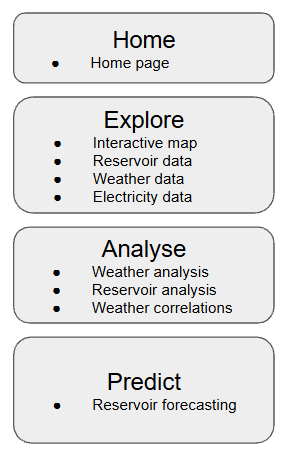

In [16]:
from IPython.display import display, Image

display(Image(filename="sketch.png", embed=True))

## Log

First I made the function to download the Euro and USD exhange rates to NOK from NB. It fetches a chosen date range, tidies the response by only keeping the date and exhange rate, and then joins the Euro and USD dataframes together by observation date. Then I tested it on data from 2024 and checked the output with a table and a Plotly plot to show that it works.

For investigating timezone differences for the APIs I checked how each of them handle time. ENTSO-E and Open-Meteo both use UTC and have hourly data. NVE uses year and ISO weeks, and Norges Bank uses business days, but both of them are based on Norwegian time. I discovered that there could be a potential issue when aggregating the hourly data into daily/weekly averages because of the timezone differences. The way to handle this is just to convert the UTC measurements to Norwegian time before aggregating, making sure the measurements fall on the right day.

The most time consuming part was the SNARIMAX forecasting. I used the NVE data for NO3 as my region and I converted the weekly data into monthly for a more resource efficient time resolution as it still keeps the same yearly trends. The montly horizons are also easier to interpret than weekly ones. I then tested different parameters, and at first it looked like differencing (d=1) helped the prediction a lot, but when tested on the later periods it showed that the improvement didn't carry over and that it only worked on the validation period. Adding more evaluation periods gave a more fair comparison, and the p=3, d=0 model performed better than the d=1 model here, but still very close to the seasonal baseline where it only beat it slightly on the 3 month horizon. I settled on that model as the default for Streamlit despite not really being stronger than the seasonal baseline. 

In the app I planned to change the navigation to data exploration, analysis and prediction. It's currently in order based on datasets, but with the new pages I feel like it would be more natural with this new order. I also want to combine the pages from assignment 1 so the reservouir plot and table are on the same page, and add the new interactable map. For refactoring I had most things done already as I have a theme, most of my plots are from Plotly, and symbols are consistent throughout. I'm also already caching most things that can be cached in Streamlit. I chose Waiting time for my bonus task, but at the time of the notebook submission I haven't fully implemented this, the map, correlations, forecasting to streamlit, nor the screencast. I will finish it as soon as I can tonight.

## AI Usage

I used ChatGPT+ mostly for getting familiar with the River framework and SARIMAX function, and to help with reasonable initial parameters for the function. It suggested how to implement it and refined my code, and helped me set up tests to make sure everything functions as it should. I have not fully gotten through the new elements and updates on Streamlit yet, so the AI usage log will be updated on Github as I go.  